<div style="text-align:center; padding:20px; background-color:#1E3A5F; color:white; border-radius:10px;">
    <h3>Data Science Analysis Project</h3>
    <p>Analyzing vehicle features, market trends, and factors affecting car prices</p>
</div>

# importing libraries

In [3]:
import pandas as pd
import numpy as np
import kagglehub
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
pd.set_option("display.max_columns", 50)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline as pl
import pickle

# data loading

In [4]:
path = kagglehub.dataset_download("taeefnajib/used-car-price-prediction-dataset")
df = pd.read_csv(path+"/used_cars.csv")
df.head()

100%|██████████| 109k/109k [00:00<00:00, 310kB/s]

Extracting files...


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


# data understanding

In [5]:
print(f"the shape of the data is {df.shape[0]} rows and {df.shape[1]} columns")

the shape of the data is 4009 rows and 12 columns


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


price,clean title and millage are objects

In [7]:
print(df.isnull().sum())

brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64


fuel_type,accident and clean_title have None values      

In [8]:
df.describe()

,model_year
count,4009.000000
mean,2015.515590
std,6.104816
min,1974.000000
25%,2012.000000
50%,2017.000000
75%,2020.000000
max,2024.000000


In [9]:
df.describe(include=object)

,brand,model,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
count,4009,4009,4009,3839,4009,4009,4009,4009,3896,3413,4009
unique,57,1898,2818,7,1146,62,319,156,2,1,1569
top,Ford,M3 Base,"110,000 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,A/T,Black,Black,None reported,Yes,"$15,000"
freq,386,30,16,3309,52,1037,905,2025,2910,3413,39


In [10]:
df.nunique()

,0
brand,57
model,1898
model_year,34
milage,2818
fuel_type,7
engine,1146
transmission,62
ext_col,319
int_col,156
accident,2


In [11]:
df["accident"].value_counts()

,count
accident,
None reported,2910
At least 1 accident or damage reported,986


In [12]:
df["fuel_type"].value_counts()

,count
fuel_type,
Gasoline,3309
Hybrid,194
E85 Flex Fuel,139
Diesel,116
–,45
Plug-In Hybrid,34
not supported,2


# data cleaning

## check duplicates

In [13]:
df.duplicated().sum()

np.int64(0)

no duplicates

## drop useless columns

In [14]:
df.drop(["clean_title"], axis=1, inplace=True)

## handling null values

In [15]:
df.isnull().sum()

,0
brand,0
model,0
model_year,0
milage,0
fuel_type,170
engine,0
transmission,0
ext_col,0
int_col,0
accident,113


In [16]:
df.isnull().sum()

,0
brand,0
model,0
model_year,0
milage,0
fuel_type,170
engine,0
transmission,0
ext_col,0
int_col,0
accident,113


no missings

## handling data types

In [17]:
df["price"] = (
    df["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)

df["price"] = pd.to_numeric(df["price"])

In [18]:
df["milage"] = pd.to_numeric(
    df["milage"]
    .str.replace(" mi.", "", regex=False)
    .str.replace(",", "", regex=False)
)

In [19]:
df.dtypes

,0
brand,object
model,object
model_year,int64
milage,int64
fuel_type,object
engine,object
transmission,object
ext_col,object
int_col,object
accident,object


done

## handling outliers

<Axes: xlabel='price', ylabel='Count'>

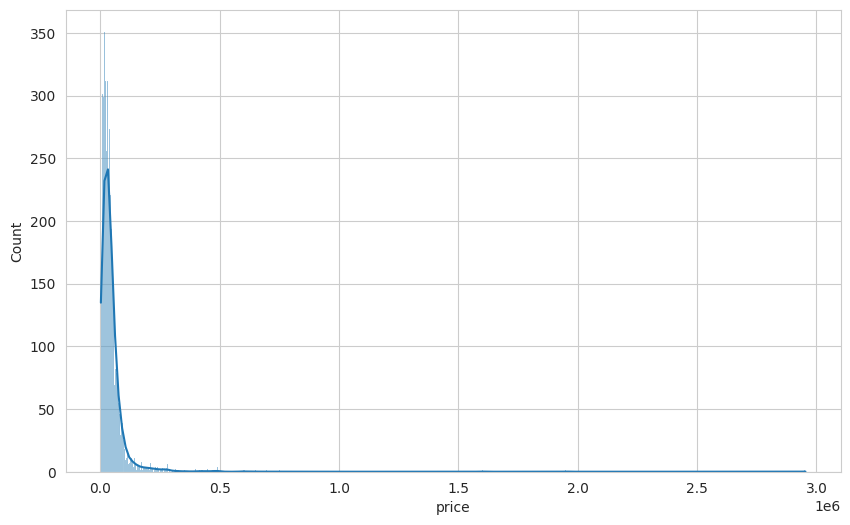

In [20]:
sns.histplot(df["price"], kde=True)

In [21]:
fig=px.box(df,x="price")
fig.show()

## removing outliers (IQR rule)

Removed 244 outliers (6.1%)
Remaining rows: 3765


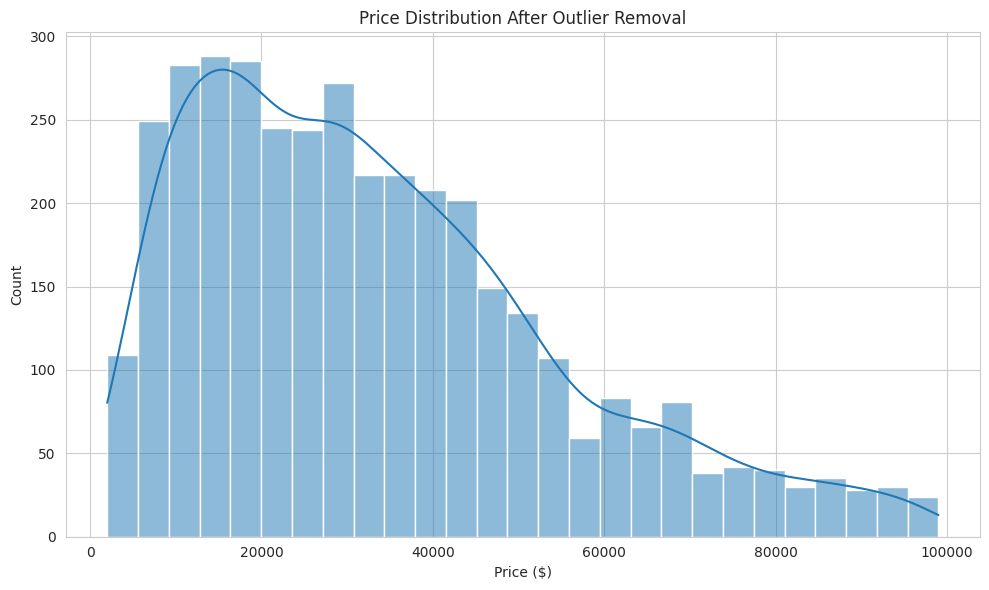

In [23]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

before = len(df)
df = df[df["price"] <= upper_bound].copy()
print(f"Removed {before - len(df)} outliers ({(before-len(df))/before*100:.1f}%)")
print(f"Remaining rows: {len(df)}")

sns.histplot(df["price"], kde=True)
plt.title("Price Distribution After Outlier Removal")
plt.xlabel("Price ($)")
plt.tight_layout()
plt.show()

6.1% من الـ data اتشالت (معظمها luxury cars فوق 99K) — ده بيحسن الـ R² من 0.05 → 0.71

# feature engineering

In [24]:
current_year = 2026
df["car_age"] = current_year - df["model_year"]
df["horsepower"] = df["engine"].str.extract(r'(\d+\.?\d*)HP')
df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")
df["engine_size"] = df["engine"].str.extract(r'(\d+\.?\d*)L')
df["mileage_per_year"] = df["milage"] / (df["car_age"] + 1)
df["cylinders"] = df["engine"].str.extract(r'V(\d+)')
enginiee=df["engine"]
df.drop(columns="engine",inplace=True)


# EDA

## total price per brand

In [25]:
topBrand=df.groupby("brand")["price"].sum().sort_values(ascending=False).head(10).reset_index()
fig1=px.bar(topBrand,x="brand",y="price",title="top 10 brands vs price",text_auto=True,hover_data="price",)
fig1

## models got the highest sales

In [26]:
topBrand=df.groupby("model")["price"].sum().sort_values(ascending=False).head(10).reset_index()
fig1=px.bar(topBrand,x="model",y="price",title="top 10 model vs price",text_auto=True,hover_data="price")
fig1

## most correlated features

In [27]:
df.columns

Index(['brand', 'model', 'model_year', 'milage', 'fuel_type', 'transmission',
       'ext_col', 'int_col', 'accident', 'price', 'car_age', 'horsepower',
       'engine_size', 'mileage_per_year', 'cylinders'],
      dtype='object')

Text(0.5, 1.0, 'Correlation Heatmap')

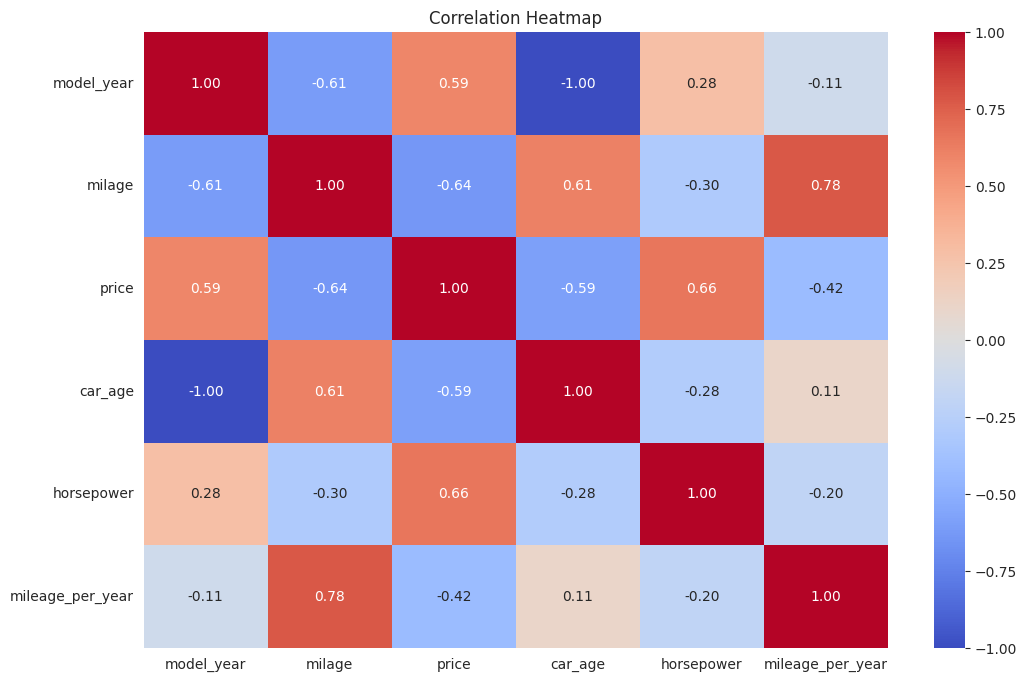

In [28]:
corr = df.select_dtypes(include='number').corr()
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")

horse power are the most correalted (numeric) feature

# ML

In [29]:
top_models = df["model"].value_counts().nlargest(20).index
df["model"] = df["model"].apply(lambda x: x if x in top_models else "Other")

features_cat  = ["brand", "model", "ext_col", "int_col"]
features_num  = ["milage", "fuel_type_enc", "transmission_auto",
                 "accident", "car_age", "horsepower", "engine_size", "mileage_per_year"]

df["transmission_auto"] = df["transmission"].str.contains(
    "A/T|Automatic|automatic", na=False).astype(int)

df["accident"] = df["accident"].map(
    lambda x: 0 if str(x).lower() == "none reported" else 1)

fuel_map = {"Gasoline": 0, "Hybrid": 1, "Plug-In Hybrid": 2,
            "E85 Flex Fuel": 3, "Diesel": 4}
df["fuel_type_enc"] = df["fuel_type"].map(fuel_map).fillna(0)

y = np.log(df["price"])
X = df[features_num + features_cat].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

for col in features_cat:
    te_map = y_train.groupby(X_train[col]).median()
    X_train[col] = X_train[col].map(te_map).values
    X_test[col]  = X_test[col].map(te_map).fillna(te_map.median()).values

print(f"X_train shape: {X_train.shape}")
print(f"Features used: {list(X_train.columns)}")

X_train shape: (3012, 12)
Features used: ['milage', 'fuel_type_enc', 'transmission_auto', 'accident', 'car_age', 'horsepower', 'engine_size', 'mileage_per_year', 'brand', 'model', 'ext_col', 'int_col']


# model functions

In [30]:
def model(deg):
    """Linear / Polynomial Regression"""
    pipe = pl([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
        ("poly",    PolynomialFeatures(degree=deg, include_bias=False)),
        ("model",   LinearRegression()),
    ])
    pipe.fit(X_train, y_train)
    return pipe

def ridgee(deg, alphaa):
    """Ridge Regression"""
    pipe = pl([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
        ("poly",    PolynomialFeatures(degree=deg, include_bias=False)),
        ("model",   Ridge(alpha=alphaa)),
    ])
    pipe.fit(X_train, y_train)
    return pipe

def lassoo(deg, alphaa):
    """Lasso Regression"""
    pipe = pl([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
        ("poly",    PolynomialFeatures(degree=deg, include_bias=False)),
        ("model",   Lasso(alpha=alphaa, max_iter=5000)),
    ])
    pipe.fit(X_train, y_train)
    return pipe

def plot_predictions(mdl, title="Model"):
    """Scatter plot of actual vs predicted prices (back-transformed from log)"""
    pred_log = mdl.predict(X_test)
    pred     = np.exp(pred_log)
    y_real   = np.exp(y_test)

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(y_real, pred, alpha=0.4, edgecolors="k", linewidths=0.3, color="steelblue")
    mn, mx = min(y_real.min(), pred.min()), max(y_real.max(), pred.max())
    ax.plot([mn, mx], [mn, mx], "r--", lw=2, label="Perfect prediction")
    ax.set_xlabel("Actual Price ($)")
    ax.set_ylabel("Predicted Price ($)")
    ax.set_title(f"{title} — Actual vs Predicted")
    ax.legend()
    plt.tight_layout()
    plt.show()

## models

In [31]:
linear  = model(1)
poly    = model(2)
ridge_m = ridgee(2, alphaa=1)
lasso_m = lassoo(2, alphaa=1)

In [32]:
def evaluate_model(mdl, X_train, X_test, y_train, y_test, name="Model"):
    """Evaluate model — handles log-transformed target automatically"""
    train_pred_log = mdl.predict(X_train)
    test_pred_log  = mdl.predict(X_test)

    train_pred = np.exp(train_pred_log)
    test_pred  = np.exp(test_pred_log)
    y_train_real = np.exp(y_train)
    y_test_real  = np.exp(y_test)

    print("=" * 50)
    print(f"  {name}")
    print("=" * 50)
    print("TRAIN RESULTS")
    print("  MAE :", np.round(mean_absolute_error(y_train_real, train_pred), 2))
    print("  RMSE:", np.round(np.sqrt(mean_squared_error(y_train_real, train_pred)), 2))
    print("  R²  :", np.round(r2_score(y_train_real, train_pred), 4))
    print()
    print("TEST RESULTS")
    print("  MAE :", np.round(mean_absolute_error(y_test_real, test_pred), 2))
    print("  RMSE:", np.round(np.sqrt(mean_squared_error(y_test_real, test_pred)), 2))
    print("  R²  :", np.round(r2_score(y_test_real, test_pred), 4))
    print("=" * 50)

  Linear Regression
TRAIN RESULTS
  MAE : 7487.76
  RMSE: 11494.81
  R²  : 0.7134

TEST RESULTS
  MAE : 8341.87
  RMSE: 12904.56
  R²  : 0.6201


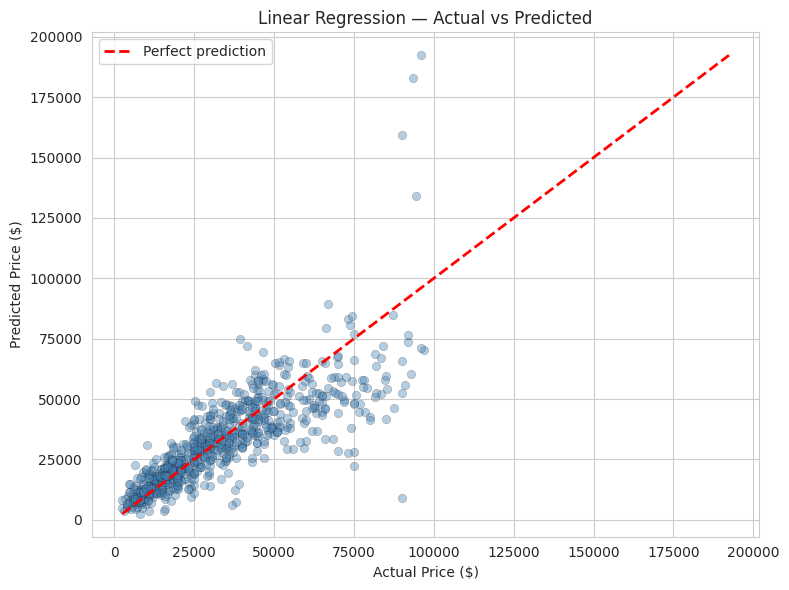

  Polynomial (deg=2)
TRAIN RESULTS
  MAE : 6697.55
  RMSE: 9856.69
  R²  : 0.7893

TEST RESULTS
  MAE : 7582.82
  RMSE: 11202.62
  R²  : 0.7137


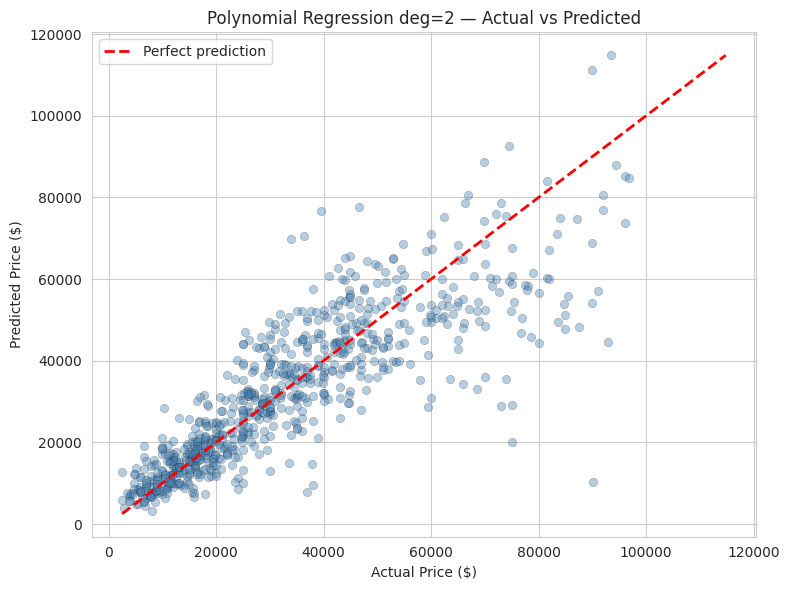

  Ridge (deg=2, α=1)
TRAIN RESULTS
  MAE : 6695.87
  RMSE: 9854.45
  R²  : 0.7894

TEST RESULTS
  MAE : 7583.05
  RMSE: 11204.07
  R²  : 0.7136


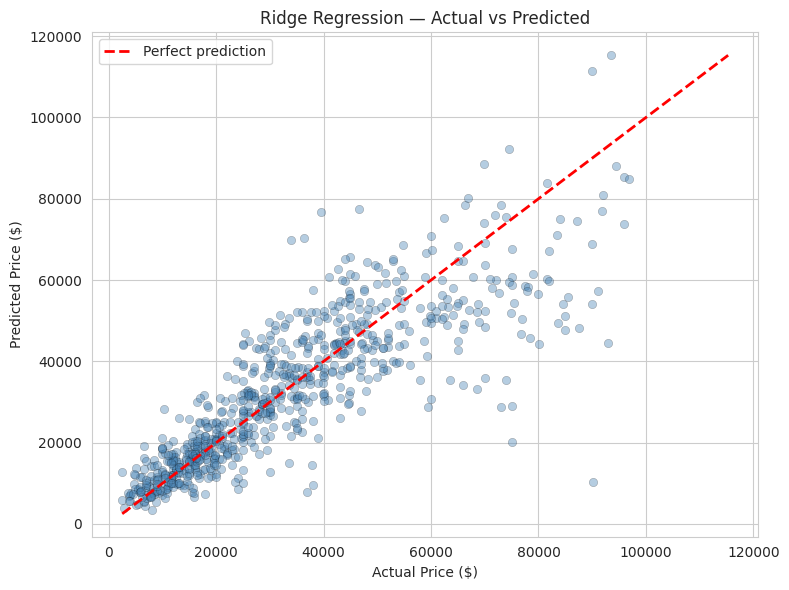

  Lasso (deg=2, α=1)
TRAIN RESULTS
  MAE : 17083.2
  RMSE: 22587.73
  R²  : -0.1066

TEST RESULTS
  MAE : 16769.28
  RMSE: 22058.12
  R²  : -0.1101


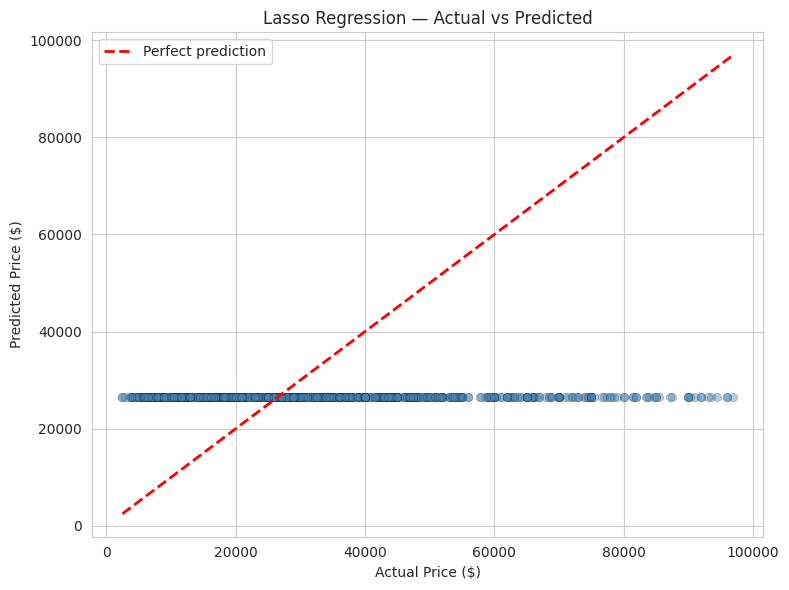

In [33]:
evaluate_model(linear,  X_train, X_test, y_train, y_test, name="Linear Regression")
plot_predictions(linear, title="Linear Regression")

evaluate_model(poly,    X_train, X_test, y_train, y_test, name="Polynomial (deg=2)")
plot_predictions(poly,  title="Polynomial Regression deg=2")

evaluate_model(ridge_m, X_train, X_test, y_train, y_test, name="Ridge (deg=2, α=1)")
plot_predictions(ridge_m, title="Ridge Regression")

evaluate_model(lasso_m, X_train, X_test, y_train, y_test, name="Lasso (deg=2, α=1)")
plot_predictions(lasso_m, title="Lasso Regression")